# LAB 23: XỬ LÝ VIDEO VÀ TÍNH TOÁN FPS VỚI OPENCV

### CELL 1: CÀI ĐẶT THƯ VIỆN

In [1]:
# Cài đặt OpenCV cho Google Colab
!pip install opencv-python-headless

# Import các thư viện cần thiết
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import HTML, display
import os

print("Đã cài đặt và import thành công tất cả thư viện!")

Đã cài đặt và import thành công tất cả thư viện!


### CELL 2: UPLOAD VIDEO

In [2]:
# Upload video từ máy tính lên Google Colab
print("Hãy chọn file video từ máy tính của bạn:")
print("Các định dạng được hỗ trợ: .mp4, .avi, .mov, .mkv")

# Upload file
uploaded = files.upload()

# Lấy tên file đã upload
if uploaded:
    video_filename = list(uploaded.keys())[0]
    print(f"Đã upload thành công: {video_filename}")

    # Kiểm tra kích thước file
    file_size = os.path.getsize(video_filename) / (1024 * 1024)  # MB
    print(f"Kích thước file: {file_size:.2f} MB")
else:
    print("Chưa upload file nào!")

Hãy chọn file video từ máy tính của bạn:
Các định dạng được hỗ trợ: .mp4, .avi, .mov, .mkv


Saving 18338415-uhd_3840_2160_60fps.mp4 to 18338415-uhd_3840_2160_60fps.mp4
Đã upload thành công: 18338415-uhd_3840_2160_60fps.mp4
Kích thước file: 11.91 MB


### CELL 3: KIỂM TRA THÔNG TIN VIDEO

In [3]:
# Hàm kiểm tra thông tin cơ bản của video
def check_video_info(video_path):
    """
    Kiểm tra và hiển thị thông tin chi tiết của video
    """
    # Mở video
    cap = cv2.VideoCapture(video_path)

    # Kiểm tra video có mở được không
    if not cap.isOpened():
        print("Không thể mở video!")
        return False

    # Lấy các thông số của video
    fps = cap.get(cv2.CAP_PROP_FPS)                    # Frames per second
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))  # Tổng số frame
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))     # Chiều rộng
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))   # Chiều cao
    duration = frame_count / fps                        # Thời lượng (giây)

    # Hiển thị thông tin
    print("THÔNG TIN VIDEO:")
    print(f"   Tên file: {video_path}")
    print(f"   Kích thước: {width} x {height} pixels")
    print(f"   FPS gốc: {fps:.2f}")
    print(f"   Tổng số frame: {frame_count}")
    print(f"   Thời lượng: {duration:.2f} giây ({duration/60:.1f} phút)")

    # Đóng video
    cap.release()
    return True

# Kiểm tra video đã upload
if 'video_filename' in globals():
    video_info_ok = check_video_info(video_filename)
else:
    print("Chưa có video để kiểm tra. Hãy chạy cell upload trước!")

THÔNG TIN VIDEO:
   Tên file: 18338415-uhd_3840_2160_60fps.mp4
   Kích thước: 3840 x 2160 pixels
   FPS gốc: 60.00
   Tổng số frame: 301
   Thời lượng: 5.02 giây (0.1 phút)


### CELL 4: HIỂN THỊ FRAME ĐẦU TIÊN

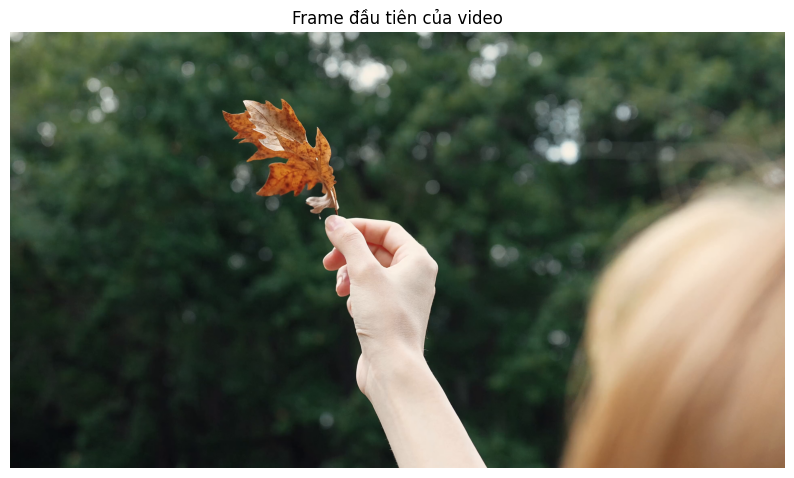

Đã hiển thị frame đầu tiên thành công!


In [4]:
# Hiển thị frame đầu tiên của video để preview
def show_first_frame(video_path):
    """
    Hiển thị frame đầu tiên của video
    """
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print("Không thể mở video!")
        return

    # Đọc frame đầu tiên
    ret, frame = cap.read()

    if ret:
        # Chuyển từ BGR sang RGB cho matplotlib
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Hiển thị
        plt.figure(figsize=(10, 6))
        plt.imshow(frame_rgb)
        plt.title("Frame đầu tiên của video")
        plt.axis('off')
        plt.show()

        print("Đã hiển thị frame đầu tiên thành công!")
    else:
        print("Không thể đọc frame đầu tiên!")

    cap.release()

# Hiển thị frame đầu tiên
if 'video_filename' in globals() and video_info_ok:
    show_first_frame(video_filename)
else:
    print("Cần upload video và kiểm tra thông tin trước!")

### CELL 5: THIẾT LẬP THAM SỐ HIỂN THỊ TEXT

In [5]:
# Cấu hình tham số để vẽ text lên video
class TextConfig:
    """
    Class chứa cấu hình để vẽ text lên video
    """
    def __init__(self):
        self.font = cv2.FONT_HERSHEY_SIMPLEX      # Font chữ
        self.font_scale = 1.2                     # Kích thước chữ
        self.font_thickness = 2                   # Độ dày chữ
        self.font_color = (0, 255, 0)            # Màu xanh lá (BGR)
        self.background_color = (0, 0, 0)        # Màu nền đen
        self.margin = 10                          # Khoảng cách từ viền

# Tạo đối tượng cấu hình
text_config = TextConfig()

# Hàm vẽ text có nền
def draw_text_with_background(img, text, position, config):
    """
    Vẽ text có nền lên image
    """
    x, y = position

    # Tính kích thước text
    (text_width, text_height), baseline = cv2.getTextSize(
        text, config.font, config.font_scale, config.font_thickness
    )

    # Vẽ nền
    cv2.rectangle(img,
                  (x - config.margin, y - text_height - config.margin),
                  (x + text_width + config.margin, y + baseline + config.margin),
                  config.background_color, -1)

    # Vẽ text
    cv2.putText(img, text, (x, y),
                config.font, config.font_scale,
                config.font_color, config.font_thickness)

print("Đã thiết lập cấu hình text thành công!")

Đã thiết lập cấu hình text thành công!


### CELL 6: HÀM TÍNH TOÁN VÀ HIỂN THỊ FPS

In [6]:
# Hàm xử lý video và tính FPS
def process_video_with_fps(video_path, max_frames=None):
    """
    Xử lý video và tính toán FPS thực thời gian

    Args:
        video_path: Đường dẫn đến file video
        max_frames: Số frame tối đa cần xử lý (None = xử lý hết)

    Returns:
        processed_frames: Danh sách các frame đã xử lý
        fps_list: Danh sách FPS của từng frame
    """

    # Mở video
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        print("Không thể mở video!")
        return None, None

    # Lấy thông tin video
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    original_fps = cap.get(cv2.CAP_PROP_FPS)

    # Giới hạn số frame nếu cần
    frames_to_process = min(max_frames or total_frames, total_frames)

    print(f"Bắt đầu xử lý {frames_to_process} frames...")
    print(f"FPS gốc của video: {original_fps:.2f}")

    # Danh sách lưu kết quả
    processed_frames = []
    fps_list = []

    frame_number = 0

    # Vòng lặp xử lý từng frame
    while frame_number < frames_to_process:

        # Bắt đầu đo thời gian
        start_time = time.time()

        #  Đọc frame từ video
        ret, frame = cap.read()

        # Kiểm tra có đọc được frame không
        if not ret:
            print(f"Không thể đọc frame {frame_number + 1}")
            break

        # Kết thúc đo thời gian
        end_time = time.time()

        # Tính toán FPS
        processing_time = end_time - start_time
        current_fps = 1.0 / processing_time if processing_time > 0 else 0

        # Tạo text hiển thị thông tin
        fps_text = f"FPS: {current_fps:.2f}"
        frame_text = f"Frame: {frame_number + 1}/{frames_to_process}"
        time_text = f"Time: {processing_time*1000:.1f}ms"

        # Vẽ thông tin lên frame
        draw_text_with_background(frame, fps_text, (30, 50), text_config)
        draw_text_with_background(frame, frame_text, (30, 100), text_config)
        draw_text_with_background(frame, time_text, (30, 150), text_config)

        # Lưu frame đã xử lý (mỗi 10 frame để tiết kiệm bộ nhớ)
        if frame_number % 10 == 0:
            processed_frames.append(frame.copy())

        # Lưu FPS
        fps_list.append(current_fps)

        # Hiển thị tiến độ
        if (frame_number + 1) % 50 == 0:
            progress = (frame_number + 1) / frames_to_process * 100
            print(f"Tiến độ: {progress:.1f}% ({frame_number + 1}/{frames_to_process})")

        frame_number += 1

    # Đóng video
    cap.release()

    print(f"Hoàn thành! Đã xử lý {len(processed_frames)} frame mẫu")
    print(f"FPS trung bình: {np.mean(fps_list):.2f}")
    print(f"FPS cao nhất: {np.max(fps_list):.2f}")
    print(f"FPS thấp nhất: {np.min(fps_list):.2f}")

    return processed_frames, fps_list

print("Đã định nghĩa hàm xử lý video thành công!")

Đã định nghĩa hàm xử lý video thành công!


### CELL 7: CHẠY XỬ LÝ VIDEO (TEST NHỎ)

In [7]:
# Test xử lý với số lượng frame nhỏ trước
TEST_FRAMES = 100  # Chỉ xử lý 100 frame đầu để test

if 'video_filename' in globals() and video_info_ok:
    print(f"CHẠY TEST với {TEST_FRAMES} frame đầu tiên...")

    # Chạy xử lý test
    test_frames, test_fps = process_video_with_fps(video_filename, TEST_FRAMES)

    if test_frames is not None:
        print(f"Test thành công! Đã tạo {len(test_frames)} frame mẫu")
    else:
        print("Test thất bại!")

else:
    print("Cần upload video trước khi chạy test!")

CHẠY TEST với 100 frame đầu tiên...
Bắt đầu xử lý 100 frames...
FPS gốc của video: 60.00
Tiến độ: 50.0% (50/100)
Tiến độ: 100.0% (100/100)
Hoàn thành! Đã xử lý 10 frame mẫu
FPS trung bình: 20.00
FPS cao nhất: 63.75
FPS thấp nhất: 5.79
Test thành công! Đã tạo 10 frame mẫu


### CELL 8: HIỂN THỊ KẾT QUẢ TEST

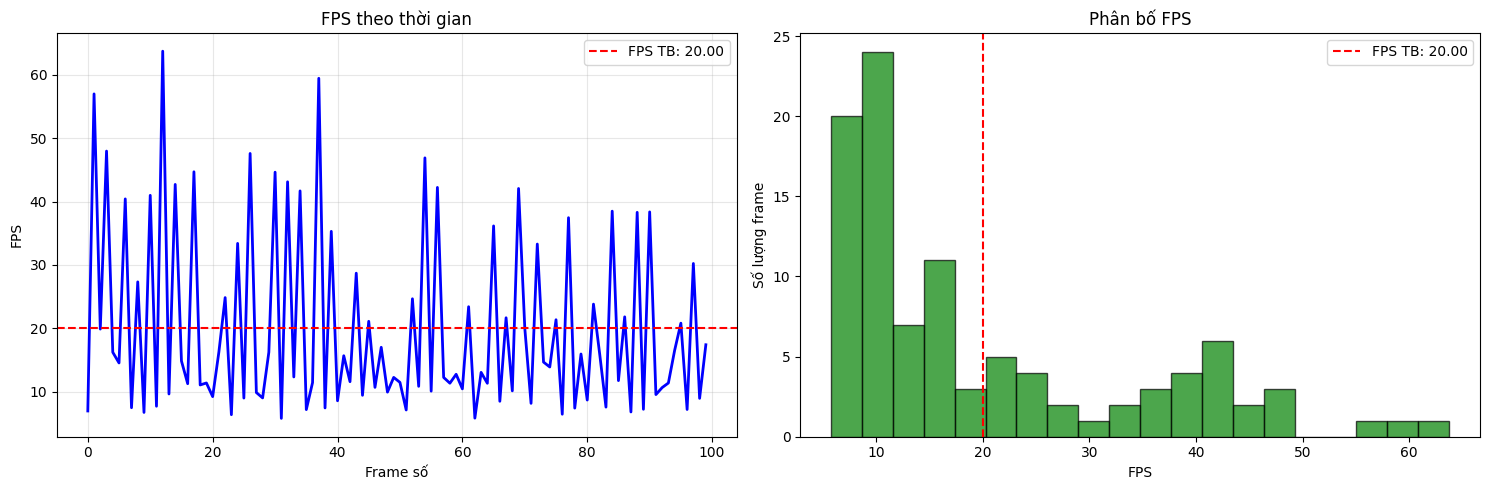


HIỂN THỊ CÁC FRAME MẪU:


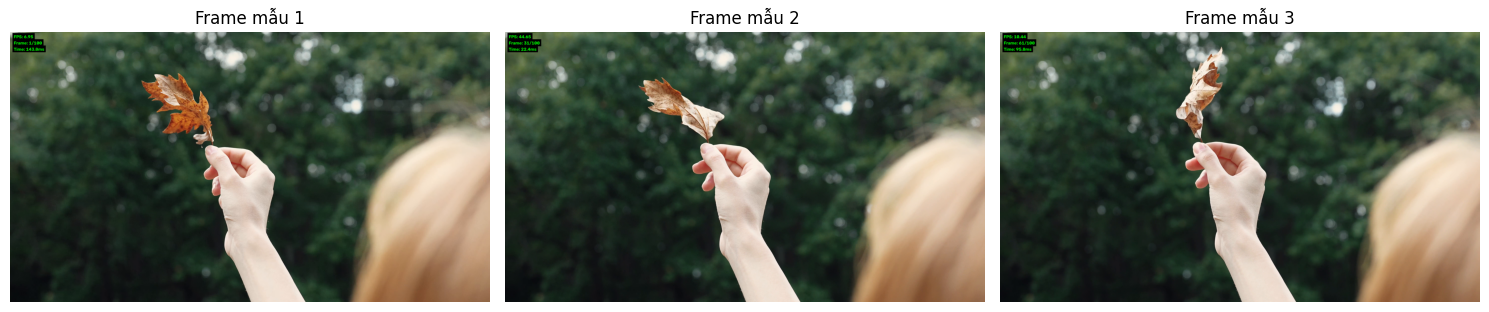

In [8]:
# Hiển thị kết quả test
if 'test_frames' in globals() and test_frames is not None:

    # Hiển thị biểu đồ FPS
    plt.figure(figsize=(15, 5))

    # Subplot 1: Biểu đồ FPS
    plt.subplot(1, 2, 1)
    plt.plot(test_fps, 'b-', linewidth=2)
    plt.title('FPS theo thời gian')
    plt.xlabel('Frame số')
    plt.ylabel('FPS')
    plt.grid(True, alpha=0.3)
    plt.axhline(y=np.mean(test_fps), color='r', linestyle='--',
                label=f'FPS TB: {np.mean(test_fps):.2f}')
    plt.legend()

    # Subplot 2: Histogram FPS
    plt.subplot(1, 2, 2)
    plt.hist(test_fps, bins=20, alpha=0.7, color='green', edgecolor='black')
    plt.title('Phân bố FPS')
    plt.xlabel('FPS')
    plt.ylabel('Số lượng frame')
    plt.axvline(x=np.mean(test_fps), color='r', linestyle='--',
                label=f'FPS TB: {np.mean(test_fps):.2f}')
    plt.legend()

    plt.tight_layout()
    plt.show()

    # Hiển thị một số frame mẫu
    print("\nHIỂN THỊ CÁC FRAME MẪU:")

    # Chọn 3 frame để hiển thị
    num_samples = min(3, len(test_frames))
    fig, axes = plt.subplots(1, num_samples, figsize=(15, 5))

    if num_samples == 1:
        axes = [axes]

    for i in range(num_samples):
        frame_idx = i * (len(test_frames) // num_samples) if len(test_frames) > num_samples else i
        frame = test_frames[frame_idx]

        # Chuyển BGR sang RGB
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        # Hiển thị
        axes[i].imshow(frame_rgb)
        axes[i].set_title(f'Frame mẫu {i+1}')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

else:
    print("Chưa có dữ liệu test để hiển thị!")

### CELL 9: XỬ LÝ TOÀN BỘ VIDEO (TÙY CHỌN)

In [9]:
# Tùy chọn: Xử lý toàn bộ video (cẩn thận với video dài!)
PROCESS_FULL_VIDEO = input("Bạn có muốn xử lý toàn bộ video không? (y/n): ").lower() == 'y'

if PROCESS_FULL_VIDEO:
    print("CẢNH BÁO: Xử lý toàn bộ video có thể mất nhiều thời gian và bộ nhớ!")

    if 'video_filename' in globals() and video_info_ok:
        print("Bắt đầu xử lý toàn bộ video...")

        # Xử lý toàn bộ video
        full_frames, full_fps = process_video_with_fps(video_filename)

        if full_frames is not None:
            print("Hoàn thành xử lý toàn bộ video!")

            # Thống kê chi tiết
            print(f"\nTHỐNG KÊ CHI TIẾT:")
            print(f"   Tổng frame xử lý: {len(full_fps)}")
            print(f"   FPS trung bình: {np.mean(full_fps):.2f}")
            print(f"   FPS cao nhất: {np.max(full_fps):.2f}")
            print(f"   FPS thấp nhất: {np.min(full_fps):.2f}")
            print(f"   Độ lệch chuẩn: {np.std(full_fps):.2f}")

        else:
            print("Xử lý toàn bộ video thất bại!")
    else:
        print("Cần upload video trước!")
else:
    print("Bỏ qua xử lý toàn bộ video.")

Bạn có muốn xử lý toàn bộ video không? (y/n): y
CẢNH BÁO: Xử lý toàn bộ video có thể mất nhiều thời gian và bộ nhớ!
Bắt đầu xử lý toàn bộ video...
Bắt đầu xử lý 301 frames...
FPS gốc của video: 60.00
Tiến độ: 16.6% (50/301)
Tiến độ: 33.2% (100/301)
Tiến độ: 49.8% (150/301)
Tiến độ: 66.4% (200/301)
Tiến độ: 83.1% (250/301)
Tiến độ: 99.7% (300/301)
Hoàn thành! Đã xử lý 31 frame mẫu
FPS trung bình: 33.66
FPS cao nhất: 100.89
FPS thấp nhất: 6.66
Hoàn thành xử lý toàn bộ video!

THỐNG KÊ CHI TIẾT:
   Tổng frame xử lý: 301
   FPS trung bình: 33.66
   FPS cao nhất: 100.89
   FPS thấp nhất: 6.66
   Độ lệch chuẩn: 20.79


### CELL 10: TẠO VIDEO OUTPUT

In [10]:
# Tạo video output với FPS counter
def create_output_video(input_path, output_path, max_duration=30):
    """
    Tạo video output có hiển thị FPS

    Args:
        input_path: Đường dẫn video input
        output_path: Đường dẫn video output
        max_duration: Thời lượng tối đa (giây) để tránh file quá lớn
    """

    # Mở video input
    cap = cv2.VideoCapture(input_path)

    if not cap.isOpened():
        print("Không thể mở video input!")
        return False

    # Lấy thông số video
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    # Giới hạn số frame
    max_frames = min(fps * max_duration, total_frames)

    print(f"Tạo video output:")
    print(f"   Kích thước: {width}x{height}")
    print(f"   FPS: {fps}")
    print(f"   Số frame: {max_frames}")

    # Tạo VideoWriter
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

    if not out.isOpened():
        print("Không thể tạo video output!")
        cap.release()
        return False

    frame_count = 0

    # Xử lý từng frame
    while frame_count < max_frames:
        start_time = time.time()

        ret, frame = cap.read()
        if not ret:
            break

        end_time = time.time()
        processing_fps = 1.0 / (end_time - start_time) if (end_time - start_time) > 0 else 0

        # Thêm thông tin lên frame
        fps_text = f"Processing FPS: {processing_fps:.2f}"
        frame_text = f"Frame: {frame_count + 1}/{max_frames}"

        draw_text_with_background(frame, fps_text, (30, 50), text_config)
        draw_text_with_background(frame, frame_text, (30, 100), text_config)

        # Ghi frame vào video output
        out.write(frame)

        frame_count += 1

        # Hiển thị tiến độ
        if frame_count % 100 == 0:
            progress = frame_count / max_frames * 100
            print(f"Tiến độ: {progress:.1f}%")

    # Đóng file
    cap.release()
    out.release()

    print(f"Đã tạo video output thành công: {output_path}")
    return True

# Tạo video output
if 'video_filename' in globals():
    output_name = f"processed_{video_filename}"

    create_success = create_output_video(video_filename, output_name)

    if create_success:
        # Hiển thị thông tin file output
        output_size = os.path.getsize(output_name) / (1024 * 1024)  # MB
        print(f"Kích thước file output: {output_size:.2f} MB")
else:
    print("Chưa có video để xử lý!")

Tạo video output:
   Kích thước: 3840x2160
   FPS: 60
   Số frame: 301
Tiến độ: 33.2%
Tiến độ: 66.4%
Tiến độ: 99.7%
Đã tạo video output thành công: processed_18338415-uhd_3840_2160_60fps.mp4
Kích thước file output: 22.91 MB


### CELL 11: DOWNLOAD VIDEO VÀ THỐNG KÊ CUỐI

In [11]:
# Download video đã xử lý và hiển thị thống kê tổng kết
if 'output_name' in globals() and os.path.exists(output_name):

    print("THỐNG KÊ TỔNG KẾT:")

    # Thống kê file
    input_size = os.path.getsize(video_filename) / (1024 * 1024)
    output_size = os.path.getsize(output_name) / (1024 * 1024)

    print(f"File gốc: {video_filename} ({input_size:.2f} MB)")
    print(f"File xử lý: {output_name} ({output_size:.2f} MB)")
    print(f"Tỷ lệ nén: {(output_size/input_size)*100:.1f}%")

    # Thống kê FPS nếu có
    if 'test_fps' in globals():
        print(f"\nTHỐNG KÊ FPS:")
        print(f"   FPS trung bình: {np.mean(test_fps):.2f}")
        print(f"   FPS cao nhất: {np.max(test_fps):.2f}")
        print(f"   FPS thấp nhất: {np.min(test_fps):.2f}")
        print(f"   Độ ổn định FPS: {(1-np.std(test_fps)/np.mean(test_fps))*100:.1f}%")

    # Download file
    print(f"\nDOWNLOAD VIDEO ĐÃ XỬ LÝ:")
    try:
        files.download(output_name)
        print("Download thành công!")
    except Exception as e:
        print(f"Lỗi download: {e}")
        print("Bạn có thể tìm file trong thư mục Files ở sidebar")

    print(f"\nHOÀN THÀNH BÀI LAB!")
    print(f"Bạn đã học được:")
    print(f"   Cách upload và đọc video bằng OpenCV")
    print(f"   Tính toán FPS thực thời gian")
    print(f"   Vẽ text thông tin lên video frame")
    print(f"   Tạo và xuất video đã xử lý")
    print(f"   Phân tích và hiển thị biểu đồ FPS")

else:
    print("Không có video output để download!")
    print("Hãy chạy lại các cell trước đó để tạo video output")

THỐNG KÊ TỔNG KẾT:
File gốc: 18338415-uhd_3840_2160_60fps.mp4 (11.91 MB)
File xử lý: processed_18338415-uhd_3840_2160_60fps.mp4 (22.91 MB)
Tỷ lệ nén: 192.4%

THỐNG KÊ FPS:
   FPS trung bình: 20.00
   FPS cao nhất: 63.75
   FPS thấp nhất: 5.79
   Độ ổn định FPS: 28.8%

DOWNLOAD VIDEO ĐÃ XỬ LÝ:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download thành công!

HOÀN THÀNH BÀI LAB!
Bạn đã học được:
   Cách upload và đọc video bằng OpenCV
   Tính toán FPS thực thời gian
   Vẽ text thông tin lên video frame
   Tạo và xuất video đã xử lý
   Phân tích và hiển thị biểu đồ FPS


### CELL BONUS: HÀM TIỆN ÍCH

In [12]:
# Các hàm tiện ích bổ sung
def analyze_video_quality(video_path):
    """Phân tích chất lượng video"""
    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        return None

    # Đọc một số frame để phân tích
    frames_to_analyze = 30
    blur_scores = []
    brightness_scores = []

    for i in range(frames_to_analyze):
        ret, frame = cap.read()
        if not ret:
            break

        # Tính độ mờ (blur) bằng Laplacian variance
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()
        blur_scores.append(blur_score)

        # Tính độ sáng trung bình
        brightness = np.mean(frame)
        brightness_scores.append(brightness)

    cap.release()

    return {
        'avg_blur': np.mean(blur_scores),
        'avg_brightness': np.mean(brightness_scores),
        'blur_stability': np.std(blur_scores),
        'brightness_stability': np.std(brightness_scores)
    }

# Phân tích chất lượng nếu có video
if 'video_filename' in globals():
    quality = analyze_video_quality(video_filename)
    if quality:
        print("PHÂN TÍCH CHẤT LƯỢNG VIDEO:")
        print(f"   Độ sắc nét: {quality['avg_blur']:.2f}")
        print(f"   Độ sáng TB: {quality['avg_brightness']:.2f}")
        print(f"   Ổn định sắc nét: {quality['blur_stability']:.2f}")
        print(f"   Ổn định độ sáng: {quality['brightness_stability']:.2f}")

print("Đã thêm các hàm tiện ích bổ sung!")

PHÂN TÍCH CHẤT LƯỢNG VIDEO:
   Độ sắc nét: 27.44
   Độ sáng TB: 78.36
   Ổn định sắc nét: 1.61
   Ổn định độ sáng: 0.20
Đã thêm các hàm tiện ích bổ sung!
